<a href="https://colab.research.google.com/github/eloisemcdonough-tech/L02-hedonic-pricing/blob/main/L2_hedonic_pricing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities?
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [Eloise]

**Date:** [11/09/26]

In [2]:
# Your Phase 1 solution to the problem goes here.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.model_selection import train_test_split

In [3]:
df = pd.read_csv("pierce_county_house_sales.csv")
print(df.shape)
print(df.columns.tolist())
print(df.head())
print(df.isna().sum())
print(df.describe())

(16814, 19)
['sale_date', 'sale_price', 'house_square_feet', 'attic_finished_square_feet', 'basement_square_feet', 'attached_garage_square_feet', 'detached_garage_square_feet', 'fireplaces', 'hvac_description', 'exterior', 'interior', 'stories', 'roof_cover', 'year_built', 'bedrooms', 'bathrooms', 'waterfront_type', 'view_quality', 'utility_sewer']
    sale_date  sale_price  house_square_feet  attic_finished_square_feet  \
0  2020-01-02      380000               2157                           0   
1  2020-01-02      383000               2238                           0   
2  2020-01-01      419900               1452                           0   
3  2020-01-02      251660                832                           0   
4  2020-01-02      500000               1780                           0   

   basement_square_feet  attached_garage_square_feet  \
0                     0                          528   
1                     0                          396   
2                     0 

In [4]:
df = df.drop(columns=["sale_date"])
cats = ["hvac_description", "exterior", "interior", "roof_cover",
        "waterfront_type", "view_quality", "utility_sewer"]
df[cats] = df[cats].fillna("None")
df = df.dropna()

In [5]:
low, high = np.percentile(df["sale_price"], [1, 99])
df = df.loc[(df["sale_price"] > low) & (df["sale_price"] < high)]
df = df.loc[df["house_square_feet"] > 0].copy()
print(df.shape)

(16474, 18)


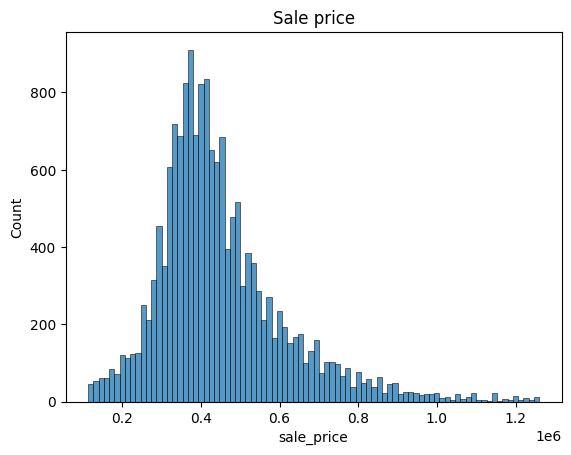

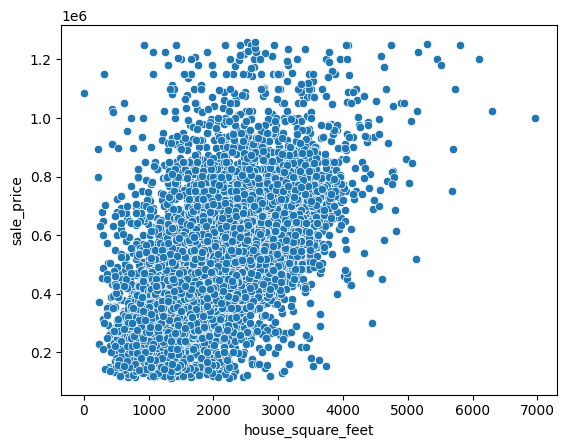

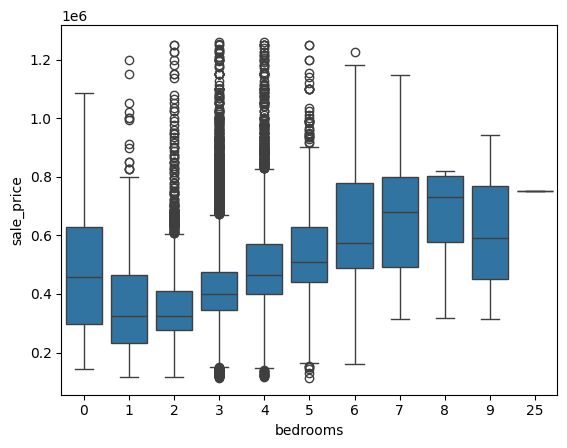

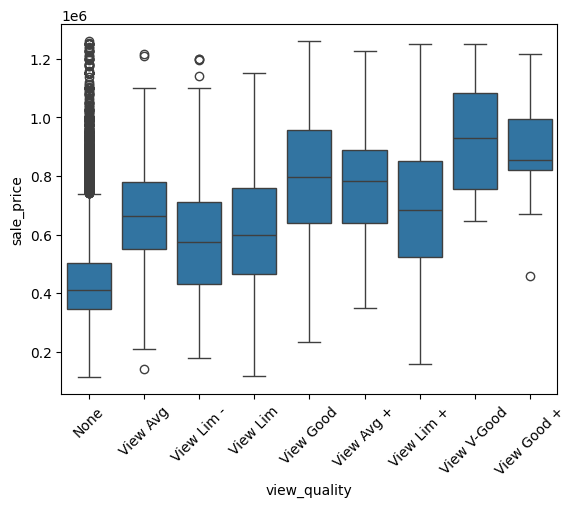

                   sale_price  house_square_feet  bathrooms  bedrooms  \
sale_price           1.000000           0.617445   0.497147  0.291291   
house_square_feet    0.617445           1.000000   0.738773  0.596244   
bathrooms            0.497147           0.738773   1.000000  0.566004   
bedrooms             0.291291           0.596244   0.566004  1.000000   
year_built           0.305712           0.546524   0.603716  0.326387   

                   year_built  
sale_price           0.305712  
house_square_feet    0.546524  
bathrooms            0.603716  
bedrooms             0.326387  
year_built           1.000000  


In [6]:
sns.histplot(df["sale_price"]); plt.title("Sale price"); plt.show()
sns.scatterplot(data=df, x="house_square_feet", y="sale_price"); plt.show()
sns.boxplot(data=df, x="bedrooms", y="sale_price"); plt.show()
sns.boxplot(data=df, x="view_quality", y="sale_price"); plt.xticks(rotation=45); plt.show()
print(df[["sale_price", "house_square_feet", "bathrooms", "bedrooms",
          "year_built"]].corr())

In [7]:
df = pd.get_dummies(df, columns=cats, drop_first=True, dtype="int")
dummy_cols = [c for c in df.columns if any(c.startswith(cat + "_") for cat in cats)]

numeric = ["house_square_feet", "attic_finished_square_feet", "basement_square_feet",
           "attached_garage_square_feet", "detached_garage_square_feet",
           "fireplaces", "stories", "year_built", "bedrooms", "bathrooms"]

In [8]:
y = df["sale_price"]
X = df.drop(columns=["sale_price"])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

In [11]:
def rmse(y, y_hat):
    return np.sqrt(np.mean((y - y_hat) ** 2))

def evaluate(features, name):
    model = LinearRegression().fit(X_train[features], y_train)
    print(name)
    print("  Train RMSE:", round(rmse(y_train, model.predict(X_train[features]))),
          " R2:", round(model.score(X_train[features], y_train), 3))
    print("  Test  RMSE:", round(rmse(y_test, model.predict(X_test[features]))),
          " R2:", round(model.score(X_test[features], y_test), 3))
    return model

m1 = evaluate(["house_square_feet"], "Model 1: square feet only")
m2 = evaluate(numeric, "Model 2: all numeric")
m3 = evaluate(numeric + dummy_cols, "Model 3: numeric + categorical")


Model 1: square feet only
  Train RMSE: 128491  R2: 0.379
  Test  RMSE: 134878  R2: 0.388
Model 2: all numeric
  Train RMSE: 112870  R2: 0.521
  Test  RMSE: 115085  R2: 0.554
Model 3: numeric + categorical
  Train RMSE: 102296  R2: 0.606
  Test  RMSE: 103707  R2: 0.638


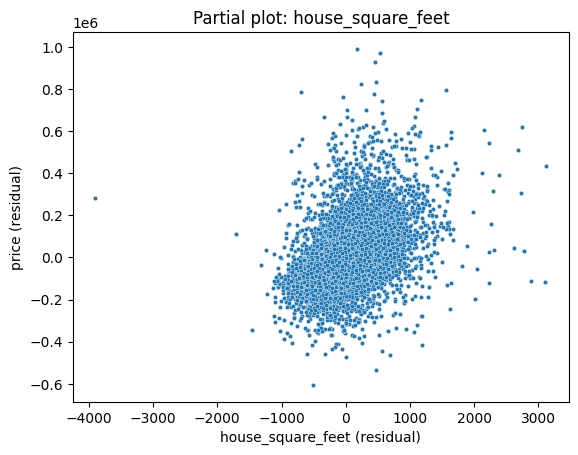

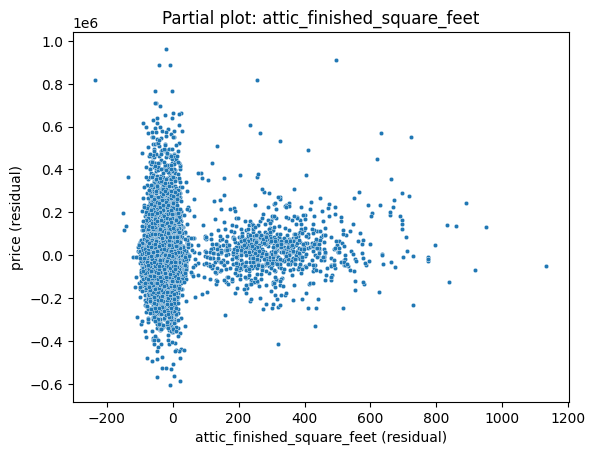

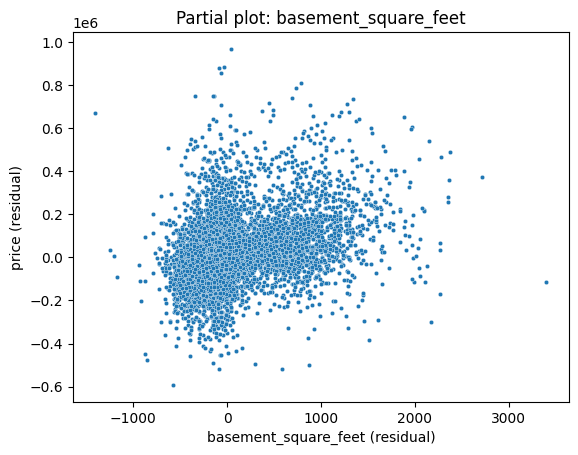

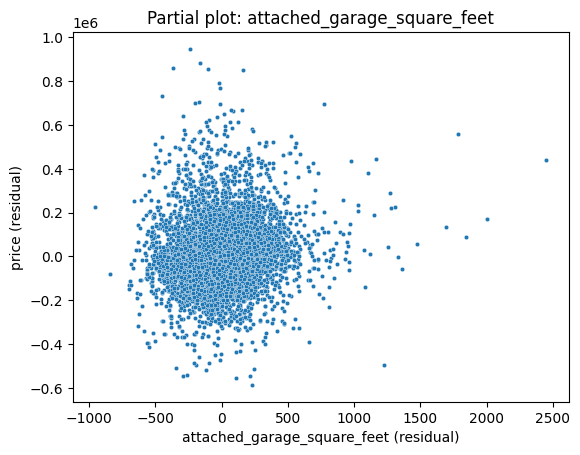

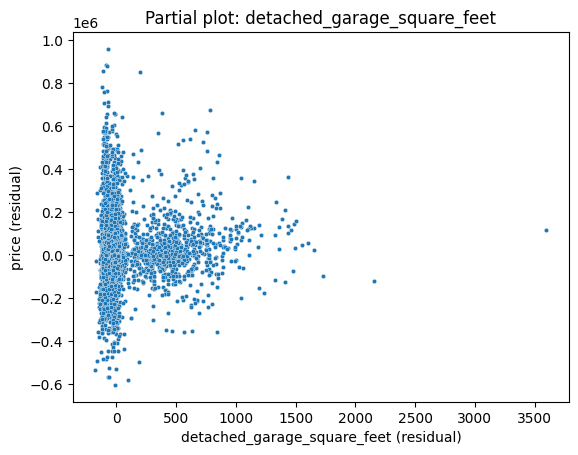

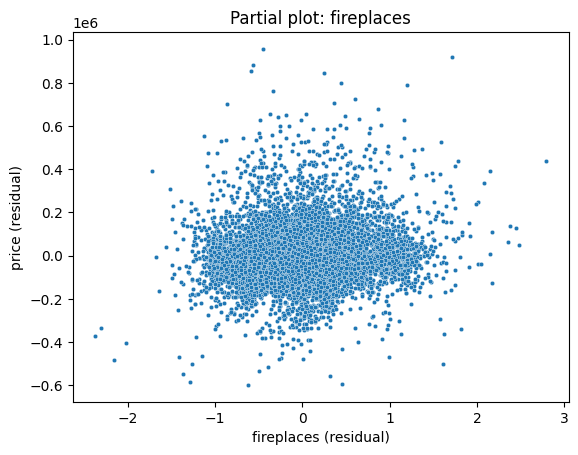

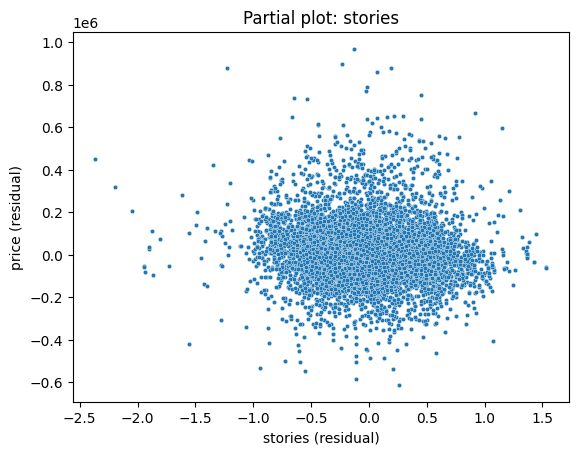

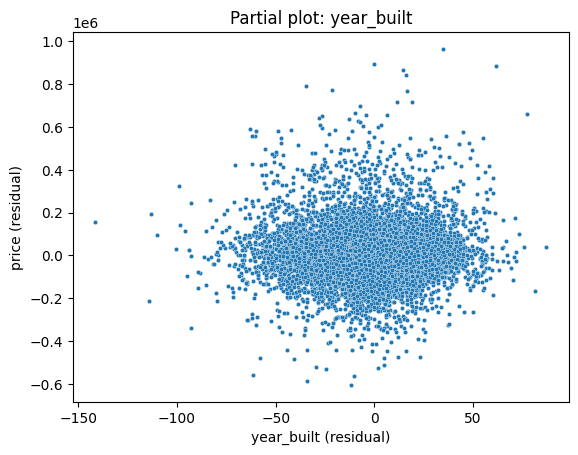

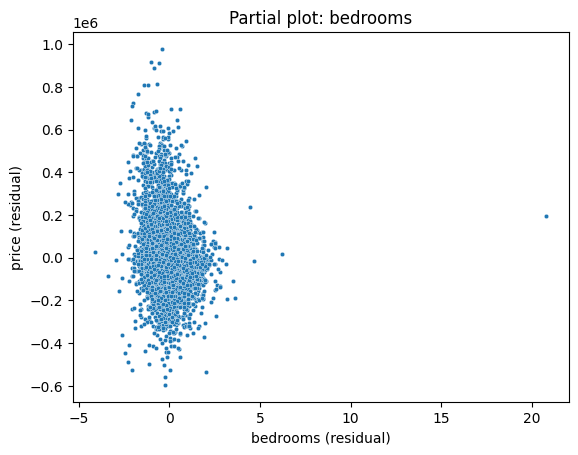

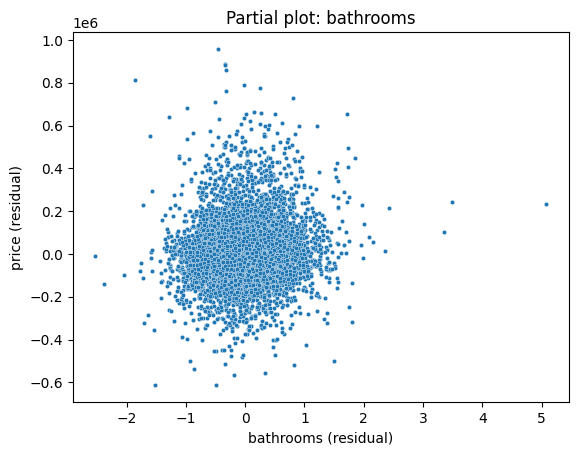

In [12]:
for v in numeric:
    others = [c for c in numeric if c != v]
    r_price = y_train - LinearRegression().fit(X_train[others], y_train).predict(X_train[others])
    r_v = X_train[v] - LinearRegression().fit(X_train[others], X_train[v]).predict(X_train[others])
    sns.scatterplot(x=r_v, y=r_price, s=10)
    plt.xlabel(v + " (residual)"); plt.ylabel("price (residual)")
    plt.title("Partial plot: " + v); plt.show()

In [14]:
for d in [X_train, X_test]:
    d["sqft_sq"] = d["house_square_feet"] ** 2
    d["year_sq"] = d["year_built"] ** 2
    d["sqft_x_bath"] = d["house_square_feet"] * d["bathrooms"]
    d["has_basement"] = (d["basement_square_feet"] > 0).astype(int)

extra = ["sqft_sq", "year_sq", "sqft_x_bath", "has_basement"]
m4 = evaluate(numeric + dummy_cols + extra, "Model 4: complex")

Model 4: complex
  Train RMSE: 101739  R2: 0.611
  Test  RMSE: 102623  R2: 0.646


In [16]:
all_feats = numeric + dummy_cols + extra
Xtr = X_train[all_feats]
Xte = X_test[all_feats]
keep = Xtr.std() > 0
Xtr, Xte = Xtr.loc[:, keep], Xte.loc[:, keep]
mean, std = Xtr.mean(), Xtr.std()
Xtr_s = (Xtr - mean) / std
Xte_s = (Xte - mean) / std

lasso = Lasso(alpha=1000, max_iter=10000).fit(Xtr_s, y_train)
coefs = pd.Series(lasso.coef_, index=Xtr.columns)
print("Selected features:\n", coefs[coefs != 0].sort_values())
print("Dropped features:", coefs[coefs == 0].index.tolist())
print("Train RMSE:", round(rmse(y_train, lasso.predict(Xtr_s))),
      " R2:", round(lasso.score(Xtr_s, y_train), 3))
print("Test  RMSE:", round(rmse(y_test, lasso.predict(Xte_s))),
      " R2:", round(lasso.score(Xte_s, y_test), 3))

Selected features:
 bedrooms                                  -13441.543303
stories                                   -11389.282698
exterior_Frame Vinyl                      -10963.285155
utility_sewer_SEWER/SEPTIC NO              -4618.627777
exterior_Pine Unfinished Cabin             -2776.970963
utility_sewer_SEWER/SEPTIC INSTALLED       -1791.598129
utility_sewer_SEWER/SEPTIC NO PERC         -1168.507350
exterior_Cedar Finished Cabin              -1149.831996
roof_cover_Composition Shingle              -921.884977
hvac_description_Forced Air                 -386.011919
roof_cover_None                              141.884931
waterfront_type_WF Stream/Creek              435.694965
hvac_description_Hot Water Baseboard         449.290376
waterfront_type_WF River                     670.724051
roof_cover_Formed Seam Metal                 728.226303
exterior_Log                                 822.297025
exterior_Cedar Unfinished Cabin             1775.868222
sqft_sq                     

ANSWERS TO QUESTIONS

Q1: Most houses sell in a fairly normal range, but a handful of really expensive ones make the price distribution right-skewed. Square footage looked like the biggest driver of price. Bathrooms tracked closely with size too (correlation around 0.74). Waterfront homes and homes with better views sold for more. To clean the data, I dropped rows with missing values and cut the top and bottom 1% of prices so the extremes wouldn’t throw things off.
Q2: I turned the categorical columns into dummy variables with drop_first=True so I wouldn’t fall into the dummy variable trap.
Q3: I split the data 80/20 into training and test sets and set random_state=0 so the results are reproducible.
Q4: The square-feet-only model was the weakest, which makes sense since it’s only one feature. The model with the numeric variables plus the categorical ones did best, Train and test scores were pretty close for all three, so none of them were overfitting.
Q5: House size and year built both showed some curvature. Price climbs faster for bigger houses, and year built has a sort of U shape, where both older and newer homes sell for more. Variables like bedrooms show up as vertical stripes because they’re whole numbers. Basement and garage have a lot of points stacked at 0 since many houses don’t have them.
Q6: For the complex model I added squared terms for size and year built, a size × bathrooms interaction, and a has-basement indicator. It improved the training R² a bit.
Q7: Size and location- or quality-type features matter most for price. The one-variable model underfits because it just doesn’t have enough information. Adding features helps up to a point, but once test performance stops improving, you’re mostly fitting noise. The big takeaway for me is to pick models by test error, not training error.
Q8: Most of what it dropped were rare categories.


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]